# Hackathon Idea - Blotto

AI Agents are especially good in solving optimisation and game theory problems. In this scenario, you will be developing an AI Agent whose job will be to create a strategy for **Blotto**.

Blotto is two-person zero sum game in which the players are tasked to simultaneously distribute limited resources over several objects (battlefields). The player devoting the most resources to a battlefield wins that battlefield, and each battlefield has a specified playoff.

Read more about Blotto here: https://en.wikipedia.org/wiki/Blotto_game

Our Hackathon-specific Blotto will follow a fictional Cambridge Vice-Chancellour election happening in 1455. Your Agent and it's opponent each have 100 *English pennies* to "donate" to the 12 Cambridge Colleges. In each college, all of it's Fellows will vote for the candidate who donated more to their college. The winner of the election is the one with the larger amount of Fellows' votes.

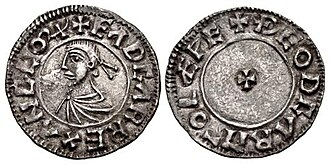

In an example game, the colleges could have the following numbers of fellows:

In [5]:
college_fellows = {
    "Peterhouse": 9,
    "Clare": 11,
    "Pembroke": 8,
    "Gonville and Caius": 12,
    "Trinity Hall": 7,
    "Corpus Christi": 9,
    "King's College": 13,
    "Queens' College": 10,
    "King's Hall": 6,
    "Michaelhouse": 5,
    "God's House": 4,
    "Buckingham College": 6,
}

A player must come up with an allocation of it's 100 *English pennies* among the colleges. For example:

In [11]:
player_donations = {
    "Peterhouse": 10,
    "Clare": 20,
    "Pembroke": 0,
    "Gonville and Caius": 20,
    "Trinity Hall": 0,
    "Corpus Christi": 10,
    "King's College": 20,
    "Queens' College": 20,
    "King's Hall": 0,
    "Michaelhouse": 0,
    "God's House": 0,
    "Buckingham College": 0,
}

Suppose their opponent allocated their funds by giving each college 2 pennies, and 40 each to *King's* and *Queen's*, the election would play out as follows:

In [35]:
donations_opponent = {"Peterhouse": 2, "Clare": 2, "Pembroke": 2, "Gonville and Caius": 2, "Trinity Hall": 2, "Corpus Christi": 2, "King's College": 40, "Queens' College": 40, "King's Hall": 2, "Michaelhouse": 2, "God's House": 2, "Buckingham College": 2}

assert sum(donations_opponent.values()) <= 100 # check within budget
assert all(isinstance(x, int) for x in donations_opponent.values()) # check no pennies cut

votes = 0
opponent_votes = 0
for college, fellows in college_fellows.items():
    if player_donations[college] > donations_opponent[college]:
        votes += fellows
    if donations[college] < donations_opponent[college]:
        opponent_votes += fellows

if votes > opponent_votes:
    print('Player won', f"{votes}:{opponent_votes}")
elif votes < opponent_votes:
    print('Player lost', f"{votes}:{opponent_votes}")
else:
    print('Draw', f"{votes}:{opponent_votes}")

Player lost 41:59


### Goal

Your goal is to create an agent that will autonomously come up with consistently good strategies to this game, and be resilient to changes in the games parameters, and rules. It will be evaluated against a pool of fake players, on 10 different games.

Define your agent below:

In [46]:
import json
import os
from openai import OpenAI

def my_agent(game_file):
    with open(f"blotto/{game_file}.json") as f:
        game = json.load(f)

    # EXPLICITLY NOT ALLOWED TO SEE OTHER PLAYERS IN EG. "blotto/players_1.json"
    client = OpenAI(
        base_url=os.getenv("LLM_API_URL"),
        api_key=os.getenv("LLM_API_KEY")
    )
    response = client.chat.completions.create(
        model="Qwen/Qwen3.8-27B-FP8",
        messages=[{
            "role": "user",
            "content": f"Develop a strong Blotto strategy for this game:\n{json.dumps(game)}\nReturn ONLY a JSON object mapping each college name to an integer number of pennies. No explanations or markdown."
        }],
        extra_body={"chat_template_kwargs": {"enable_thinking": False}}
    )

    strategy = json.loads(response.choices[0].message.content)
    return strategy

In [55]:
my_agent("game_1")

{'Peterhouse': 10,
 'Clare': 12,
 'Pembroke': 9,
 'Gonville and Caius': 13,
 'Trinity Hall': 8,
 'Corpus Christi': 10,
 "King's College": 14,
 "Queens' College": 11,
 "King's Hall": 7,
 'Michaelhouse': 6,
 "God's House": 5,
 'Buckingham College': 7}

### Run the code below to evaluate your agent:

In [56]:
%run blotto/generate_players.py
# creates competitors


Game 1:
  ✓ Even Steven
  ✓ Proportional Percy
  ✓ Majority Mary
  ✓ Tactical Thomas
  ✓ Random Robin
  ✓ Selective Simon
  ✓ Penny Pincher
  ✓ Greedy Geoffrey
  ✓ Devious Douglas
  Optimising Chaos Charles...
  ✓ Chaos Charles
  Optimising Ambush Arthur...
  ✓ Ambush Arthur
  Optimising Mastermind Margaret...
  ✓ Mastermind Margaret
  Calling Qwen the Conqueror...
  ✓ Qwen the Conqueror
  Calling Kimi the Third...
  ✓ Kimi the Third
  Calling Lord GLM...
  ✗ Lord GLM: Expecting value: line 1 column 1 (char 0)
Saved 14 competitors to /workspace/workshop/hackathon/blotto/players_1.json

Game 2:
  ✓ Even Steven
  ✓ Proportional Percy
  ✓ Majority Mary
  ✓ Tactical Thomas
  ✓ Random Robin
  ✓ Selective Simon
  ✓ Penny Pincher
  ✓ Greedy Geoffrey
  ✓ Devious Douglas
  Optimising Chaos Charles...
  ✓ Chaos Charles
  Optimising Ambush Arthur...
  ✓ Ambush Arthur
  Optimising Mastermind Margaret...
  ✓ Mastermind Margaret
  Calling Qwen the Conqueror...
  ✓ Qwen the Conqueror
  Calling Kimi 

In [57]:
import json
import pandas as pd
from pathlib import Path

results = {}

for game_file in sorted(Path("blotto").glob("game_*.json")):
    number = game_file.stem.split("_")[-1]
    players_file = game_file.with_name(f"players_{number}.json")
    if not players_file.exists():
        continue

    game = json.loads(game_file.read_text())
    players = json.loads(players_file.read_text())
    exec(game["evaluation_function"], globals())

    scores = {name: 0.0 for name in players}
    players["My Agent"] = my_agent(f"game_{number}")
    scores["My Agent"] = 0.0

    for name1, allocation1 in players.items():
        for name2, allocation2 in players.items():
            if name1 == name2:
                continue
            scores[name1] += evaluate(allocation1, allocation2, game["college_fellows"])

    results[f"Game {number}"] = scores

df = pd.DataFrame(results)
df["Total"] = df.sum(axis=1)
df = df.sort_values("Total", ascending=False)
df.index.name = "Player"
display(df.style.format("{:.1f}").apply(lambda row: ["color: red; font-weight: bold" if row.name == "My Agent" else "" for _ in row], axis=1).map_index(lambda x: "color: red; font-weight: bold" if x == "My Agent" else "", axis=0))

,Game 1,Game 2,Game 3,Game 4,Game 5,Total
Player,,,,,,
Majority Mary,13.0,13.0,12.0,12.0,13.0,63.0
Tactical Thomas,13.0,12.5,13.0,10.0,13.0,61.5
Chaos Charles,11.0,11.0,11.0,10.0,8.0,51.0
Ambush Arthur,12.0,10.5,6.0,5.0,12.0,45.5
Proportional Percy,10.0,8.5,9.5,8.0,9.0,45.0
Mastermind Margaret,8.0,8.0,6.5,9.0,11.5,43.0
Qwen the Conqueror,7.0,11.0,6.0,2.0,10.5,36.5
Random Robin,6.0,6.0,6.0,7.0,6.0,31.0
Devious Douglas,1.0,1.0,14.0,13.0,0.5,29.5


### Holdout Problem

While improving your Agentic system, you probably made some decisions based on improvements on the leaderboard. This could be *overfitting*. To verify your agent's actual performance, check it against the holdout dataset provided below.

This problem set further tests your Agent's *robustness* - resiliance to unexpected changes. The sets of colleges might be different, and some will come with ammended rules.

**Only test your agent on the holdout problems once**